In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import os

In [2]:
# Load patient segmentation data
clustered_data = pd.read_csv(
    "../outputs/clustered_patient_features.csv"
)

# Load cluster analysis results
cluster_summary = pd.read_csv(
    "../outputs/cluster_kpi_summary.csv"
)

# Load business recommendations
recommendations = pd.read_csv(
    "../outputs/cluster_recommendations.csv"
)

# Load hospital analysis results
hospital_summary = pd.read_csv(
    "../outputs/hospital_wise_summary.csv"
)

hospital_cluster = pd.read_csv(
    "../outputs/hospital_cluster_distribution.csv"
)

print("All project files loaded successfully.")

print("Clustered Data:", clustered_data.shape)
print("Cluster Summary:", cluster_summary.shape)
print("Recommendations:", recommendations.shape)
print("Hospital Summary:", hospital_summary.shape)
print("Hospital Cluster:", hospital_cluster.shape)

All project files loaded successfully.
Clustered Data: (50000, 15)
Cluster Summary: (4, 10)
Recommendations: (4, 5)
Hospital Summary: (4, 7)
Hospital Cluster: (4, 5)


In [3]:
print("PATIENT SEGMENTATION SUMMARY")

cluster_distribution = (
    clustered_data["Cluster"]
    .value_counts()
    .sort_index()
    .reset_index()
)

cluster_distribution.columns = ["Cluster", "Patient_Count"]

cluster_distribution["Percentage"] = (
    cluster_distribution["Patient_Count"] /
    len(clustered_data) * 100
)

display(cluster_distribution.round(2))

PATIENT SEGMENTATION SUMMARY


,Cluster,Patient_Count,Percentage
0,0,4713,9.43
1,1,20717,41.43
2,2,4723,9.45
3,3,19847,39.69


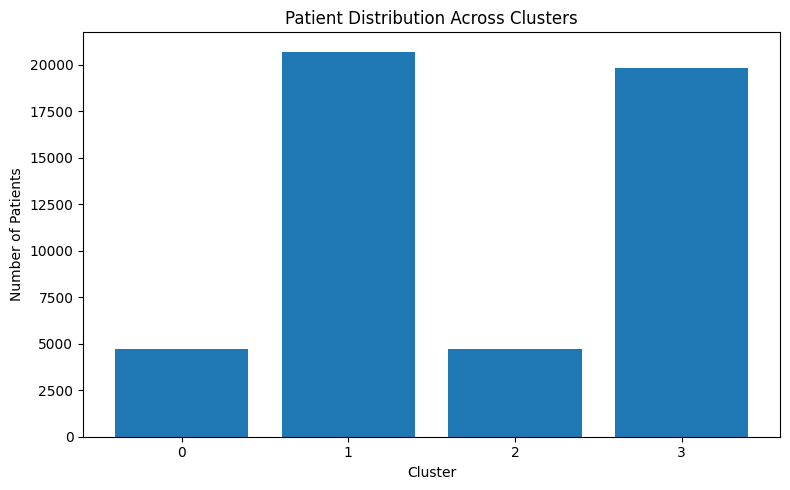

In [4]:
plt.figure(figsize=(8, 5))

plt.bar(
    cluster_distribution["Cluster"].astype(str),
    cluster_distribution["Patient_Count"]
)

plt.title("Patient Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

In [5]:
print("CLUSTER-WISE KPI SUMMARY")

display(cluster_summary)

CLUSTER-WISE KPI SUMMARY


,Cluster,Patient_Count,Average_Recency,Average_OPD_Visits,Average_Billing,Total_Billing,Average_Admissions,Average_LOS,Average_Lab_Tests,Patient_Percentage
0,0,4713,730.00,0.00,3945.74,1.859628e+07,0.40,1.61,1.25,9.43
1,1,20717,152.74,5.15,13629.26,2.823574e+08,1.69,5.43,3.36,41.43
2,2,4723,259.87,2.29,2.24,1.056393e+04,0.42,1.63,1.32,9.45
3,3,19847,223.82,3.15,7724.85,1.533152e+08,0.05,0.11,1.92,39.69


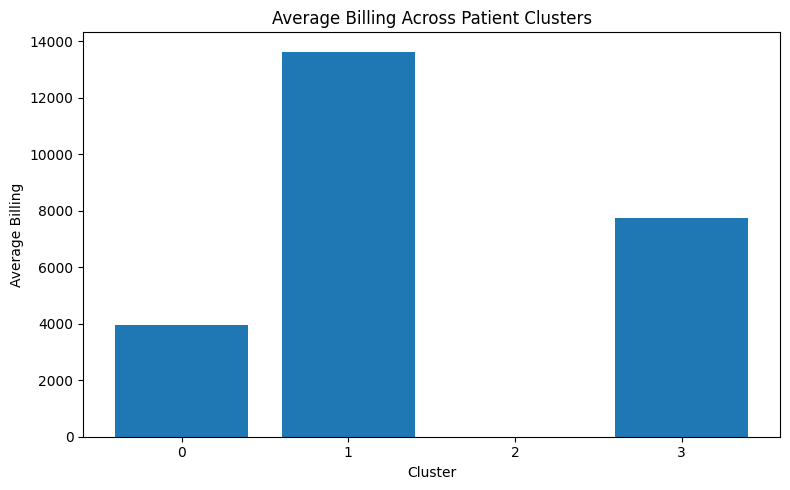

In [6]:
plt.figure(figsize=(8, 5))

plt.bar(
    cluster_summary["Cluster"].astype(str),
    cluster_summary["Average_Billing"]
)

plt.title("Average Billing Across Patient Clusters")
plt.xlabel("Cluster")
plt.ylabel("Average Billing")

plt.tight_layout()
plt.show()

In [7]:
print("HOSPITAL-WISE PERFORMANCE SUMMARY")

display(hospital_summary)

HOSPITAL-WISE PERFORMANCE SUMMARY


,hospital_id,Patient_Count,Percentage,Total_OPD_Visits,Total_Billing,Average_Billing,hospital_name
0,H001,15926,31.85,57275,1.435995e+08,2822.71,Hyderabad Central Hospital
1,H002,11532,23.06,41516,1.043355e+08,2833.82,Secunderabad Care Hospital
2,H003,12565,25.13,45383,1.153716e+08,2842.16,Kukatpally Community Hospital
3,H004,9977,19.95,35826,9.097278e+07,2868.36,LB Nagar Community Hospital


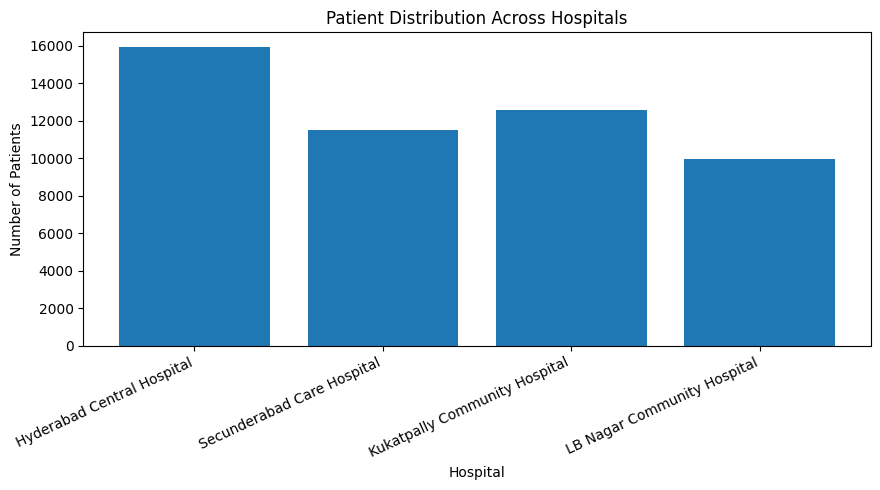

In [8]:
plt.figure(figsize=(9, 5))

plt.bar(
    hospital_summary["hospital_name"],
    hospital_summary["Patient_Count"]
)

plt.title("Patient Distribution Across Hospitals")
plt.xlabel("Hospital")
plt.ylabel("Number of Patients")

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

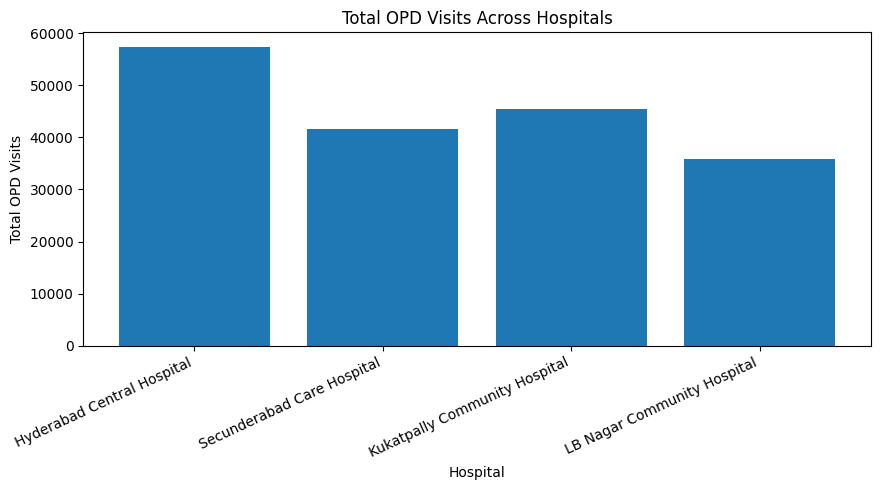

In [9]:
plt.figure(figsize=(9, 5))

plt.bar(
    hospital_summary["hospital_name"],
    hospital_summary["Total_OPD_Visits"]
)

plt.title("Total OPD Visits Across Hospitals")
plt.xlabel("Hospital")
plt.ylabel("Total OPD Visits")

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [10]:
print("FINAL BUSINESS RECOMMENDATIONS")

display(recommendations)

FINAL BUSINESS RECOMMENDATIONS


,Cluster,Segment,Recommended_Action,Estimated_Cost_Per_Patient,Expected_Target
0,0,No Recent OPD Activity,Send appointment reminders and follow-up messages,50,10% increase in OPD reactivation
1,1,High Utilization Patients,Introduce personalized preventive health check...,300,10% increase in preventive check-up participation
2,2,Low Billing Patients,Review billing records and improve billing dat...,40,Improve billing record completeness by 15%
3,3,OPD-Focused Patients,Promote appropriate preventive health screenin...,150,10% increase in screening participation


In [11]:
print("FINAL PROJECT VALIDATION")

print("Total Patients:", len(clustered_data))
print("Number of Clusters:", clustered_data["Cluster"].nunique())
print("Number of Hospitals:", len(hospital_summary))

print("\nCluster Distribution:")
print(cluster_distribution)

print("\nHospital Distribution:")
print(
    hospital_summary[
        ["hospital_name", "Patient_Count", "Percentage"]
    ]
)

print("\nValidation Completed Successfully.")

FINAL PROJECT VALIDATION
Total Patients: 50000
Number of Clusters: 4
Number of Hospitals: 4

Cluster Distribution:
   Cluster  Patient_Count  Percentage
0        0           4713       9.426
1        1          20717      41.434
2        2           4723       9.446
3        3          19847      39.694

Hospital Distribution:
                   hospital_name  Patient_Count  Percentage
0     Hyderabad Central Hospital          15926       31.85
1     Secunderabad Care Hospital          11532       23.06
2  Kukatpally Community Hospital          12565       25.13
3    LB Nagar Community Hospital           9977       19.95

Validation Completed Successfully.


In [12]:
print("""
PROJECT CONCLUSION

The Hospital Segmentation Study was conducted to identify
different groups of patients based on their healthcare
utilization and behavioural patterns.

Data cleaning, exploratory data analysis, RFM feature
engineering and feature scaling were performed before
applying the K-Means clustering algorithm.

Four patient segments were identified using the Elbow
Method and Silhouette Score.

Cluster profiling helped understand differences in patient
activity, billing, admissions and laboratory usage.

Hospital-wise analysis provided an overview of patient
distribution, OPD visits and billing across four hospitals.

Based on the identified segments, targeted business
recommendations were proposed to support patient engagement
and hospital planning.

The study uses synthetic data and its findings are intended
for educational and analytical demonstration.
""")


PROJECT CONCLUSION

The Hospital Segmentation Study was conducted to identify
different groups of patients based on their healthcare
utilization and behavioural patterns.

Data cleaning, exploratory data analysis, RFM feature
engineering and feature scaling were performed before
applying the K-Means clustering algorithm.

Four patient segments were identified using the Elbow
Method and Silhouette Score.

Cluster profiling helped understand differences in patient
activity, billing, admissions and laboratory usage.

Hospital-wise analysis provided an overview of patient
distribution, OPD visits and billing across four hospitals.

Based on the identified segments, targeted business
recommendations were proposed to support patient engagement
and hospital planning.

The study uses synthetic data and its findings are intended
for educational and analytical demonstration.

